## Liver cancer

In [1]:
import pandas as pd
import os

In [2]:
# 加载数据集
file_path = '../ELIFE pancancer ready-to-use data.csv'
data = pd.read_csv(file_path)

In [ ]:
positive_samples = data[data['Diagnosis'] == "Liver cancer"]
negative_samples = data[data['Label'] == 0]

num_negative = len(positive_samples) * 2  # 负样本数量是正样本的 1 倍
negative_samples = negative_samples.sample(n=num_negative, random_state=42)  # 随机采样负样本
positive_samples_upsampled = positive_samples.sample(n=len(positive_samples)*2, replace=True, random_state=42)

# 合并正负样本
Liver_sample = pd.concat([positive_samples_upsampled, negative_samples], ignore_index=True)
Liver_sample = Liver_sample.drop(columns=["Cohort", "Diagnosis"])
Liver_sample.to_csv("Liver_sample.csv", index=False)

### Fscore

In [ ]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold

file_path = "Liver_sample_FscoreSorted.csv"
data = pd.read_csv(file_path)

In [ ]:
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(
        Liver_sample,
        y=Liver_sample["class"],
        groups=Liver_sample["SampleID"]
    )
)

train_data = Liver_sample.iloc[train_idx]
test_data = Liver_sample.iloc[test_idx]

train_data = train_data.drop(columns=["SampleID"])
test_data = test_data.drop(columns=["SampleID"])

X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [12]:
all_features = X_train.columns.tolist()
auc_train_scores_Fscore = []
auc_val_scores_Fscore = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.1
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 10
max_decline_tolerance = 5

In [13]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_Fscore.append(auc_train)
    auc_val_scores_Fscore.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >=40:
        break

    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
{2}
验证集 AUC 开始下降（0.8932 → 0.8856），连续次数：1
{3}
{4}
{5}
验证集 AUC 开始下降（0.9175 → 0.9172），连续次数：1
{6}
验证集 AUC 开始下降（0.9172 → 0.9112），连续次数：2
{7}
{8}
验证集 AUC 开始下降（0.9116 → 0.9027），连续次数：1
{9}
{10}
{11}
验证集 AUC 开始下降（0.9096 → 0.9060），连续次数：1
{12}
验证集 AUC 开始下降（0.9060 → 0.9030），连续次数：2
{13}
{14}
{15}
{16}
验证集 AUC 开始下降（0.9142 → 0.9057），连续次数：1
{17}
验证集 AUC 开始下降（0.9057 → 0.9001），连续次数：2
{18}
{19}
验证集 AUC 开始下降（0.9668 → 0.9661），连续次数：1
{20}
验证集 AUC 开始下降（0.9661 → 0.9609），连续次数：2
{21}
{22}
验证集 AUC 开始下降（0.9668 → 0.9661），连续次数：1
{23}
{24}
{25}
验证集 AUC 开始下降（0.9704 → 0.9694），连续次数：1
{26}
{27}
{28}
验证集 AUC 开始下降（0.9747 → 0.9744），连续次数：1
{29}
{30}
验证集 AUC 开始下降（0.9770 → 0.9740），连续次数：1
{31}
{32}
{33}
验证集 AUC 开始下降（0.9767 → 0.9750），连续次数：1
{34}
{35}
验证集 AUC 开始下降（0.9822 → 0.9770），连续次数：1
{36}
{37}
{38}
验证集 AUC 开始下降（0.9816 → 0.9796），连续次数：1
{39}
验证集 AUC 开始下降（0.9796 → 0.9776），连续次数：2
{40}
选择的特征数: 34, 最佳验证集 AUC: 0.9822, 对应的训练集 AUC：0.9654


In [16]:
Liver_sample_FscoreSorted = pd.read_csv("Liver_sample_FscoreSorted.csv")
Liver_sample_FscoreSorted_selected34 = Liver_sample_FscoreSorted.iloc[:, :35]
Liver_sample_FscoreSorted_selected34.to_csv("../Fscore/Liver_sample_FscoreSorted_selected34.csv", index=False)

In [14]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_Fscore) + 1),
    "Train_AUC": auc_train_scores_Fscore,
    "Validation_AUC": auc_val_scores_Fscore
})

auc_df.to_csv("AUC_scores_Fscore.csv", index=False)

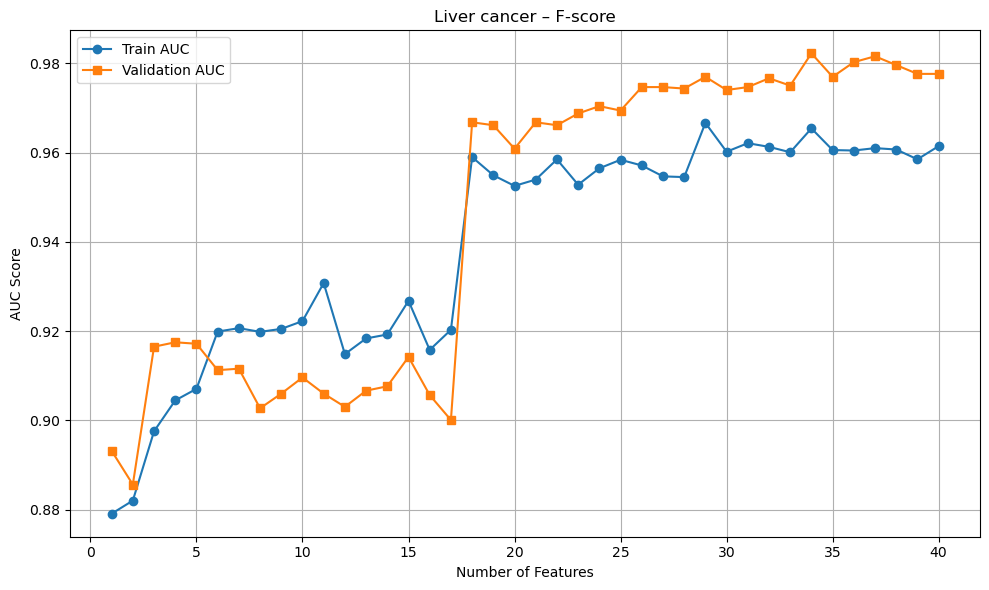

In [41]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_Fscore.csv")

# 绘制图像
plt.figure(figsize=(10, 6))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("Liver cancer – F-score")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_Fscore.png", dpi=300)
plt.show()


### ANOVA

In [8]:
import pandas as pd

# 1. 读取最终的 CSV 文件
csv_file = "Liver_sample_AnovaSorted.csv"
df = pd.read_csv(csv_file)

# 2. 读取 ANOVA 排序的特征文件，获取正确的特征名顺序
anova_sorted_file = "../ANOVA/Liver_feature_importance.csv" 
with open(anova_sorted_file, "r") as f:
    sorted_feature_names = [line.split()[1] for line in f.readlines()]  # 取出特征名称

# 3. 获取当前 CSV 文件的列名（去掉第一列 class）
original_column_names = list(df.columns[1:])  # 去掉第 1 列类别标签

# 4. 创建新的列名列表（保持类别标签不变）
new_column_names = ["class"] + sorted_feature_names[:len(original_column_names)]

# 5. 重新设置 DataFrame 的列名
df.columns = new_column_names

# 6. 保存修改后的 CSV 文件
df.to_csv("Liver_sample_AnovaSorted_corrected.csv", index=False)


In [17]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "Liver_sample_AnovaSorted_corrected.csv"
data = pd.read_csv(file_path)

In [ ]:
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(
        Liver_sample,
        y=Liver_sample["class"],
        groups=Liver_sample["SampleID"]
    )
)

train_data = Liver_sample.iloc[train_idx]
test_data = Liver_sample.iloc[test_idx]

train_data = train_data.drop(columns=["SampleID"])
test_data = test_data.drop(columns=["SampleID"])

X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [24]:
all_features = X_train.columns.tolist()
auc_train_scores_ANOVA = []
auc_val_scores_ANOVA = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.1  
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 10
max_decline_tolerance = 5

In [25]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_ANOVA.append(auc_train)
    auc_val_scores_ANOVA.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >=40:
        break
    
    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
{2}
验证集 AUC 开始下降（0.8932 → 0.8856），连续次数：1
{3}
{4}
{5}
验证集 AUC 开始下降（0.9175 → 0.9172），连续次数：1
{6}
验证集 AUC 开始下降（0.9172 → 0.9112），连续次数：2
{7}
{8}
验证集 AUC 开始下降（0.9116 → 0.9027），连续次数：1
{9}
{10}
{11}
验证集 AUC 开始下降（0.9096 → 0.9060），连续次数：1
{12}
验证集 AUC 开始下降（0.9060 → 0.9030），连续次数：2
{13}
{14}
{15}
{16}
验证集 AUC 开始下降（0.9142 → 0.9057），连续次数：1
{17}
验证集 AUC 开始下降（0.9057 → 0.9001），连续次数：2
{18}
{19}
验证集 AUC 开始下降（0.9668 → 0.9661），连续次数：1
{20}
验证集 AUC 开始下降（0.9661 → 0.9609），连续次数：2
{21}
{22}
验证集 AUC 开始下降（0.9668 → 0.9661），连续次数：1
{23}
{24}
{25}
验证集 AUC 开始下降（0.9704 → 0.9694），连续次数：1
{26}
{27}
{28}
验证集 AUC 开始下降（0.9747 → 0.9744），连续次数：1
{29}
{30}
验证集 AUC 开始下降（0.9770 → 0.9740），连续次数：1
{31}
{32}
{33}
验证集 AUC 开始下降（0.9767 → 0.9750），连续次数：1
{34}
{35}
验证集 AUC 开始下降（0.9822 → 0.9770），连续次数：1
{36}
{37}
{38}
验证集 AUC 开始下降（0.9816 → 0.9796），连续次数：1
{39}
验证集 AUC 开始下降（0.9796 → 0.9776），连续次数：2
{40}
选择的特征数: 34, 最佳验证集 AUC: 0.9822, 对应的训练集 AUC：0.9654


In [56]:
Liver_sample_AnovaSorted_corrected = pd.read_csv("Liver_sample_AnovaSorted_corrected.csv")
Liver_sample_AnovaSorted_selected34 = Liver_sample_AnovaSorted_corrected.iloc[:, :35]
Liver_sample_AnovaSorted_selected34.to_csv("../ANOVA/Liver_sample_AnovaSorted_selected34.csv", index=False)

In [26]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_ANOVA) + 1),
    "Train_AUC": auc_train_scores_ANOVA,
    "Validation_AUC": auc_val_scores_ANOVA
})

auc_df.to_csv("AUC_scores_ANOVA.csv", index=False)

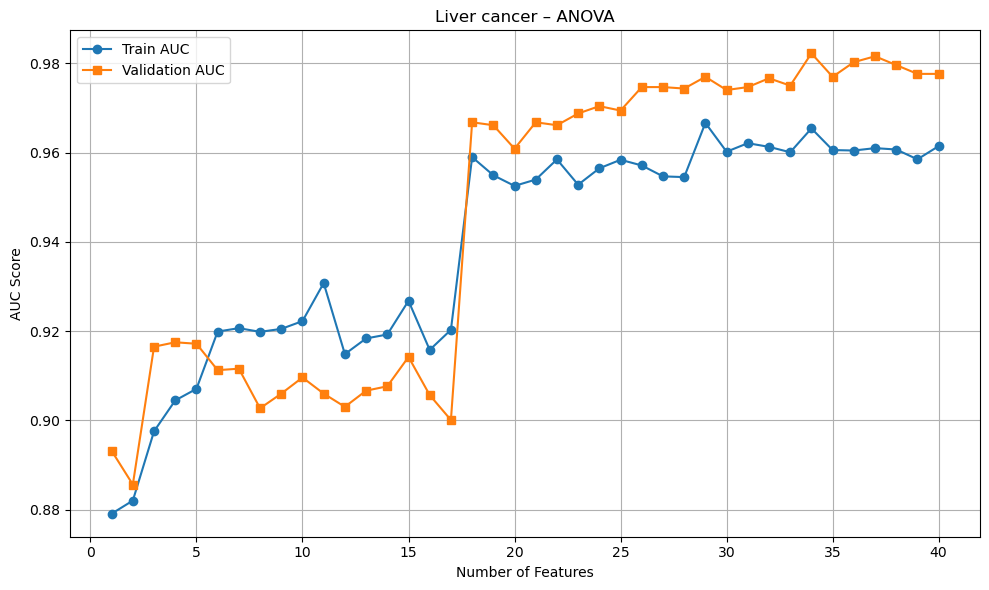

In [42]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_ANOVA.csv")

# 绘制图像
plt.figure(figsize=(10, 6))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("Liver cancer – ANOVA")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_ANOVA.png", dpi=300)
plt.show()


### ReliefF

In [23]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "Liver_sample_ReliefFSorted.csv"
data = pd.read_csv(file_path)

In [ ]:
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(
        Liver_sample,
        y=Liver_sample["class"],
        groups=Liver_sample["SampleID"]
    )
)

train_data = Liver_sample.iloc[train_idx]
test_data = Liver_sample.iloc[test_idx]

train_data = train_data.drop(columns=["SampleID"])
test_data = test_data.drop(columns=["SampleID"])

X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [11]:
all_features = X_train.columns.tolist()
auc_train_scores_ReliefF = []
auc_val_scores_ReliefF = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.2
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 10
max_decline_tolerance = 5

In [15]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_ReliefF.append(auc_train)
    auc_val_scores_ReliefF.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >=20:
        break
    
    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{31}
选择的特征数: 20, 最佳验证集 AUC: 0.9954, 对应的训练集 AUC：0.9908


In [16]:
Liver_sample_ReliefFSorted = pd.read_csv("Liver_sample_ReliefFSorted.csv")
Liver_sample_ReliefFSorted_selected11 = Liver_sample_ReliefFSorted.iloc[:, :12]
Liver_sample_ReliefFSorted_selected11.to_csv("../ReliefF/Liver_sample_ReliefFSorted_selected11.csv", index=False)

In [13]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_ReliefF) + 1),
    "Train_AUC": auc_train_scores_ReliefF,
    "Validation_AUC": auc_val_scores_ReliefF
})

auc_df.to_csv("AUC_scores_ReliefF.csv", index=False)

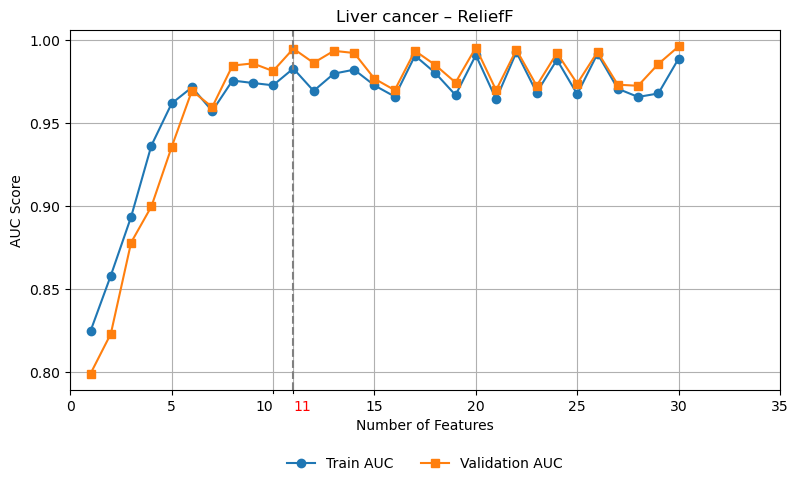

In [20]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_ReliefF.csv")

# 绘制图像
plt.figure(figsize=(8, 5))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("Liver cancer – ReliefF")
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.grid(True)
plt.yticks([0.80, 0.85, 0.90, 0.95, 1.00])
plt.tight_layout()

# 添加竖线标注特征数 = 11
plt.axvline(x=11, color='gray', linestyle='--', linewidth=1.5)

# 设置 x 轴刻度并强制包含 11
xticks = sorted(set(plt.xticks()[0].tolist() + [11]))
plt.xticks(xticks)

# 调整标签位置
ax = plt.gca()
for label in ax.get_xticklabels():
    text = label.get_text()
    if text == '11':
        # 向右微调0.3个单位，设置左对齐
        label.set_x(label.get_position()[0])
        label.set_horizontalalignment('left')
        label.set_color('red')
        label.set_bbox({'facecolor': 'white', 'alpha': 0.9, 'edgecolor': 'none'})
    elif text == '10':
        # 向左微调0.3个单位，设置右对齐
        label.set_x(label.get_position()[0])
        label.set_horizontalalignment('right')
        label.set_bbox({'facecolor': 'white', 'alpha': 0.9, 'edgecolor': 'none'})

# 保持网格线在原始位置
ax.xaxis.set_ticks_position('bottom')  # 确保刻度线位置不变

# 调整坐标轴范围防止溢出
ax.set_xlim(left=0, right=max(auc_df["Num_Features"]) + 5)

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_ReliefF.png", dpi=300)
plt.show()


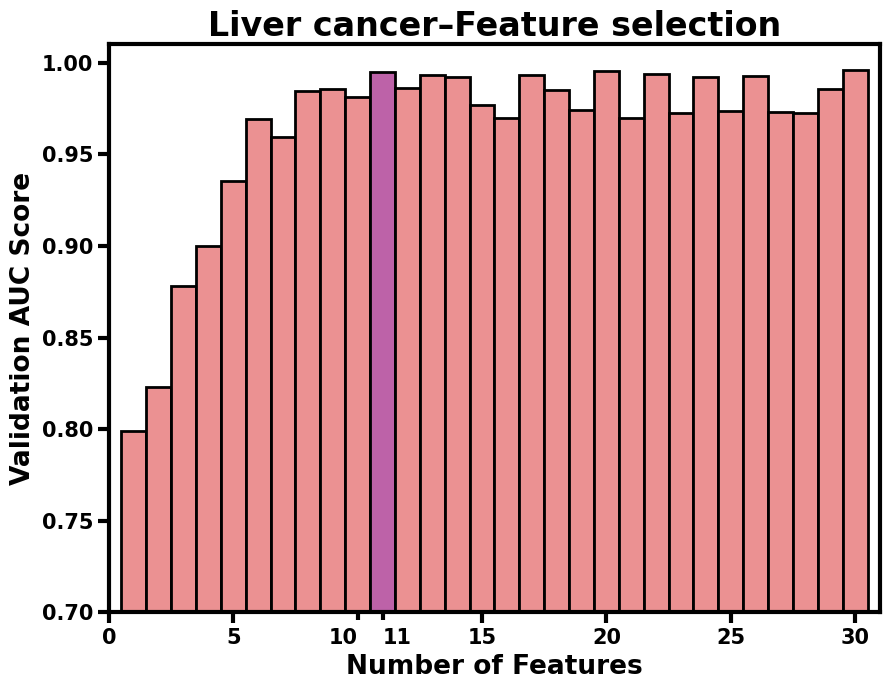

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_ReliefF.csv")

# 绘图
plt.figure(figsize=(9, 7))

# 绘制验证集 AUC 的条形图，无空隙，有边框
x = auc_df["Num_Features"]
bar_colors = ['#bd62a8' if val == 11 else '#eb9192' for val in auc_df["Num_Features"]]
plt.bar(x, auc_df["Validation_AUC"], width=1.0, color=bar_colors, edgecolor='black', linewidth=2, label='Validation AUC')

# 设置 x 轴刻度并强制包含 11
xticks = sorted(set(plt.xticks()[0].tolist() + [11]))
plt.xticks(xticks)

# 调整标签位置
ax = plt.gca()
for label in ax.get_xticklabels():
    text = label.get_text()
    x, y = label.get_position()
    
    if text == '10':
        # 向左微调 0.3 单位
        # label.set_position((x - 0.5, y))
        label.set_horizontalalignment('right')
        label.set_bbox({'facecolor': 'white', 'alpha': 1, 'edgecolor': 'none'})
        
    elif text == '11':
        # 向右微调 0.3 单位
        # label.set_position((x + 0.5, y))
        label.set_horizontalalignment('left')
        # label.set_color('#d3521f')
        label.set_bbox({'facecolor': 'white', 'alpha': 1, 'edgecolor': 'none'})

# 调整特定刻度标签样式
# ax = plt.gca()
# for label in ax.get_xticklabels():
#     text = label.get_text()
#     if text == '11':
#         label.set_x(label.get_position()[0])
#         label.set_color('red')

# 设置标签、标题和样式
plt.xlabel("Number of Features", fontsize=19, fontweight='bold')
plt.ylabel("Validation AUC Score", fontsize=19, fontweight='bold')
plt.title("Liver cancer–Feature selection", fontsize=24, fontweight='bold')
# plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=1, frameon=False)

# 设置均匀的 y 轴刻度从 0.70 到 1.00
plt.yticks(np.arange(0.70, 1.01, 0.05))
ax.set_ylim(0.70, 1.01)

# 去掉网格线
plt.grid(False)

# 限制 x 轴范围
ax.set_xlim(left=0, right=31)
ax.xaxis.set_ticks_position('bottom')

ax = plt.gca()  # 获取当前坐标轴
for spine in ax.spines.values():
    spine.set_linewidth(3)
ax.tick_params(axis='both', width=3, length=8)
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
    tick_label.set_fontsize(15)
    tick_label.set_fontweight('bold')

plt.tight_layout()
plt.savefig("AUC_vs_FeatureCount_ReliefF_BarOnlyVal.png", dpi=300)
plt.show()


### Binomial

In [44]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "Liver_sample_BinomialSorted.csv"
data = pd.read_csv(file_path)

In [ ]:
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(
        Liver_sample,
        y=Liver_sample["class"],
        groups=Liver_sample["SampleID"]
    )
)

train_data = Liver_sample.iloc[train_idx]
test_data = Liver_sample.iloc[test_idx]

train_data = train_data.drop(columns=["SampleID"])
test_data = test_data.drop(columns=["SampleID"])

X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [51]:
all_features = X_train.columns.tolist()
auc_train_scores_Binomial = []
auc_val_scores_Binomial = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.25
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 30
max_decline_tolerance = 5

In [52]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_Binomial.append(auc_train)
    auc_val_scores_Binomial.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >=40:
        break

    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
{2}


{3}
{4}
{5}
{6}
验证集 AUC 开始下降（0.8074 → 0.7890），连续次数：1
{7}
{8}
{9}
{10}
{11}
验证集 AUC 开始下降（0.8771 → 0.8764），连续次数：1
{12}
验证集 AUC 开始下降（0.8764 → 0.8679），连续次数：2
{13}
{14}
{15}
验证集 AUC 开始下降（0.9007 → 0.8547），连续次数：1
{16}
{17}
验证集 AUC 开始下降（0.8797 → 0.8646），连续次数：1
{18}
{19}
验证集 AUC 开始下降（0.8895 → 0.8790），连续次数：1
{20}
{21}
{22}
验证集 AUC 开始下降（0.9139 → 0.8856），连续次数：1
{23}
验证集 AUC 开始下降（0.8856 → 0.8639），连续次数：2
{24}
{25}
验证集 AUC 开始下降（0.8961 → 0.8836），连续次数：1
{26}
{27}
验证集 AUC 开始下降（0.8974 → 0.8928），连续次数：1
{28}
{29}
{30}
{31}
验证集 AUC 开始下降（0.9343 → 0.9066），连续次数：1
{32}
{33}
验证集 AUC 开始下降（0.9165 → 0.9034），连续次数：1
{34}
{35}
验证集 AUC 开始下降（0.9362 → 0.9027），连续次数：1
{36}
{37}
验证集 AUC 开始下降（0.9323 → 0.9250），连续次数：1
{38}
验证集 AUC 开始下降（0.9250 → 0.9191），连续次数：2
{39}
{40}
选择的特征数: 34, 最佳验证集 AUC: 0.9362, 对应的训练集 AUC：0.9897


In [55]:
Liver_sample_BinomialSorted = pd.read_csv("Liver_sample_BinomialSorted.csv")
Liver_sample_BinomialSorted_selected34 = Liver_sample_BinomialSorted.iloc[:, :35]
Liver_sample_BinomialSorted_selected34.to_csv("../Binomial/Liver_sample_BinomialSorted_selected34.csv", index=False)

In [53]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_Binomial) + 1),
    "Train_AUC": auc_train_scores_Binomial,
    "Validation_AUC": auc_val_scores_Binomial
})

auc_df.to_csv("AUC_scores_Binomial.csv", index=False)

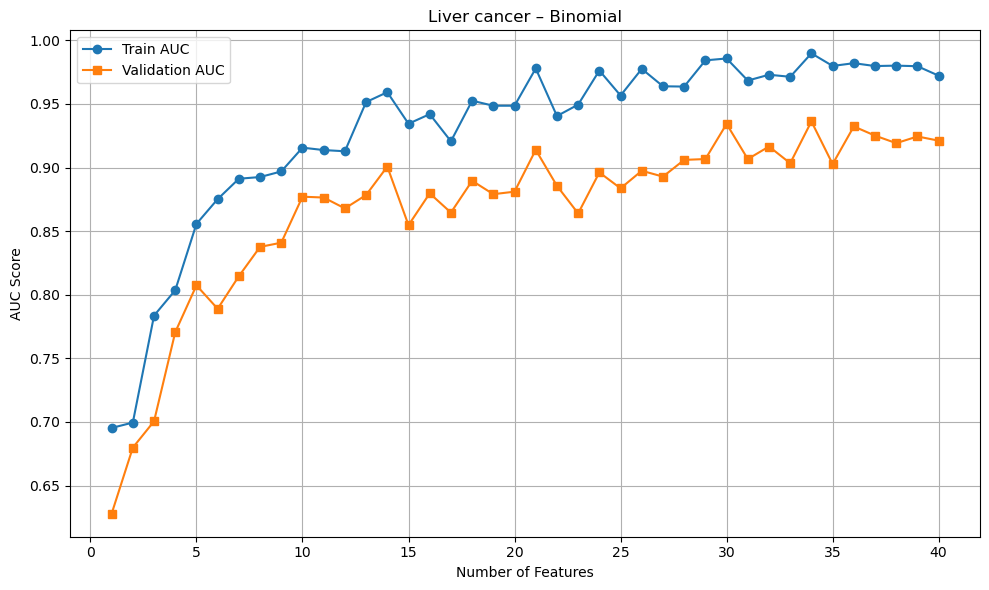

In [54]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_Binomial.csv")

# 绘制图像
plt.figure(figsize=(10, 6))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("Liver cancer – Binomial")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_Binomial.png", dpi=300)
plt.show()

### biomaker分析

In [1]:
import pandas as pd

file_paths = [
    "../ANOVA/Liver_sample_AnovaSorted_selected34.csv",
    "../Binomial/Liver_sample_BinomialSorted_selected34.csv",
    "../Fscore/Liver_sample_FscoreSorted_selected34.csv",
    "../ReliefF/Liver_sample_ReliefFSorted_selected20.csv"
]
dfs = [pd.read_csv(file_path) for file_path in file_paths]
dfs_info = [df.head() for df in dfs]


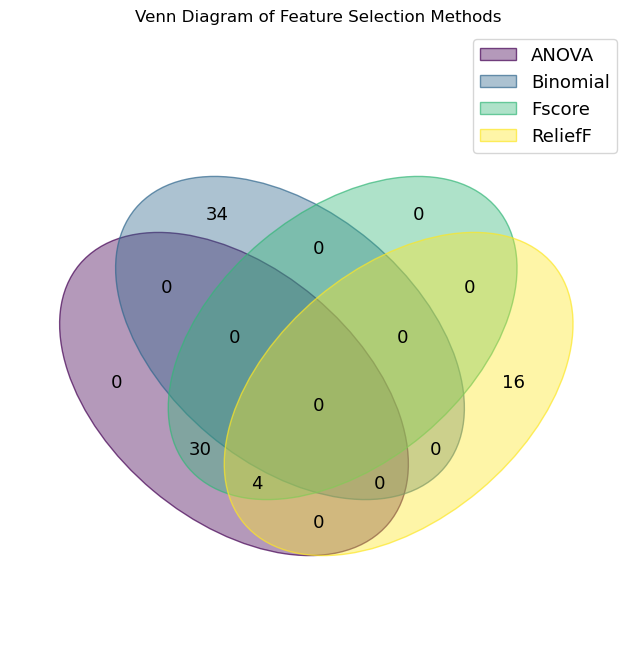

In [2]:
import matplotlib.pyplot as plt
from venn import venn
import pandas as pd

# 加载所有文件
df_anova = dfs[0]
df_binomial = dfs[1]
df_fscore = dfs[2]
df_reliefF = dfs[3]

# 提取每个文件的特征列
anova_features = set(df_anova.columns[1:])
binomial_features = set(df_binomial.columns[1:])
fscore_features = set(df_fscore.columns[1:])
relieff_features = set(df_reliefF.columns[1:])

feature_sets = {
    'ANOVA': anova_features,
    'Binomial': binomial_features,
    'Fscore': fscore_features,
    'ReliefF': relieff_features
}

venn(feature_sets)
plt.title("Venn Diagram of Feature Selection Methods")
plt.show()